# Brisbane City Council Contact Centre — Demand, Channel Shift & 2027 Forecast

**Business question:** how has demand on Brisbane City Council's Contact Centre changed between 2014 and 2026 —
the move from phone to digital channels, seasonal and weekly peaks, and the services that drive contacts —
and how many calls, and how many phone agents, should the Council plan for in 2027?

**Data:** Brisbane City Council, *Contact Centre – Customer enquiries* (open data, CC BY 4.0), daily contact volumes
by channel, site, category and service, 1 Jan 2014 – 30 Sep 2026. Loading, cleaning and data-quality checks are in
`sql/00`–`02` and documented in `data_governance.md`. Every business question is answered in SQL
(`sql/03_business_analysis.sql`); this notebook runs those queries, draws the charts, and builds the forecast.

**Conventions:** demand = **inbound** contacts only · Australian financial years (FY2026 = Jul 2025 – Jun 2026) ·
year-on-year views use complete years FY2015–FY2026 except FY2019 (Jan–Jun 2019 was never published) · "calls" = channel *Voice In*.

In [1]:
import re, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import holidays
from sqlalchemy import create_engine, text
from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160, "display.max_columns", 20)

engine = create_engine("postgresql+psycopg2://postgres@localhost:5432/bcc_contact_centre")
IMG = Path("images"); IMG.mkdir(exist_ok=True)

def q(sql):
    with engine.connect() as con:
        return pd.read_sql(text(sql), con)

# Statements of sql/03_business_analysis.sql, in file order:
# 0 view · 1 Q1 · 2 Q2 · 3 Q3 · 4 Q4 · 5 Q5 · 6 Q6 · 7 Q7a · 8 Q7b · 9 Q8 · 10 Q9
raw = Path("sql/03_business_analysis.sql").read_text(encoding="utf-8")
STMTS = [s.strip() for s in re.split(r";\s*\n", raw) if re.sub(r"--[^\n]*", "", s).strip()]
with engine.begin() as con:
    con.execute(text(STMTS[0]))          # (re)create core.v_enquiries
run = lambda i: q(STMTS[i])
print(len(STMTS), "statements loaded")

11 statements loaded


In [2]:
# Chart style — reference palette (light mode), thin marks, recessive grid
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
S1, S2, S3, S4, S5 = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
OTHER = "#a8a7a2"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "font.size": 10.5, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.titlepad": 24, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
})
thousands = mtick.FuncFormatter(lambda x, _: f"{x/1e3:,.0f}k")
def save(fig, name):
    fig.savefig(IMG / name); plt.show()

## 0. Data quality — what the analysis can and cannot trust

In [3]:
display(q("SELECT step, step_name, rows_in, rows_out, volume_in, volume_out FROM governance.cleaning_log ORDER BY step"))
display(q('''SELECT r.rule_id, q.dimension, q.rule, r.failing, r.status
             FROM governance.dq_results r JOIN governance.dq_rules q USING (rule_id) ORDER BY 1'''))

,step,step_name,rows_in,rows_out,volume_in,volume_out
0,1,Raw load,1707129,1707129,19893926,19893926
1,2,Cast types + validate volume,1707129,1707129,19893926,19893926
2,3,Quarantine missing dates,1707129,1696849,19893926,19583461
3,4,Collapse duplicate keys,1696849,1696778,19583461,19583461
4,5,Map channels,1696778,1696778,19583461,19583461
5,6,"Build fact + calendar, flag coverage gaps",1696778,1696778,19583461,19583461


,rule_id,dimension,rule,failing,status
0,DQ01,Completeness,Every source row has a date,10280,Pass (within threshold)
1,DQ02,Validity,volume is a positive integer,0,Pass
2,DQ03,Validity,Dates fall between 2014-01-01 and the extract ...,0,Pass
3,DQ04,Validity,work_site is Call Centre or Business Centre,0,Pass
4,DQ05,Uniqueness,One row per date × channel × work_site × categ...,0,Pass
5,DQ06,Consistency,Every channel exists in core.dim_channel,0,Pass
6,DQ07,Completeness,Every calendar day in the range has data,181,Known issue
7,DQ08,Timeliness,Latest date is no more than 60 days before the...,0,Pass
8,DQ09,Reconciliation,Clean volume + quarantined volume = raw volume,0,Pass


## Q1–Q2. Is demand growing, and where is it going?
Inbound demand per financial year, split by channel group (mail, fax, social media and SMS folded into *Other*).

,financial_year,inbound,change_vs_prior_pct
0,2015,1431004,NaN
1,2016,1488148,4.0
2,2017,1475952,-0.8
3,2018,1438492,-2.5
4,2020,1385761,-3.7
5,2021,1422706,2.7
6,2022,1414993,-0.5
7,2023,1324051,-6.4
8,2024,1483901,12.1
9,2025,1589762,7.1


channel_group,Phone,Web & online forms,Email,Face-to-face,Other
financial_year,,,,,
2015,83.6,6.6,2.6,6.0,1.2
2016,76.8,12.2,3.5,6.2,1.4
2017,76.7,13.0,3.2,5.6,1.5
2018,75.3,14.4,3.6,5.3,1.4
2020,72.3,18.4,4.3,3.9,1.2
2021,66.0,25.6,4.4,3.2,0.8
2022,64.0,26.9,5.8,2.7,0.6
2023,62.7,27.2,6.3,3.3,0.5
2024,58.9,31.5,6.4,2.8,0.4


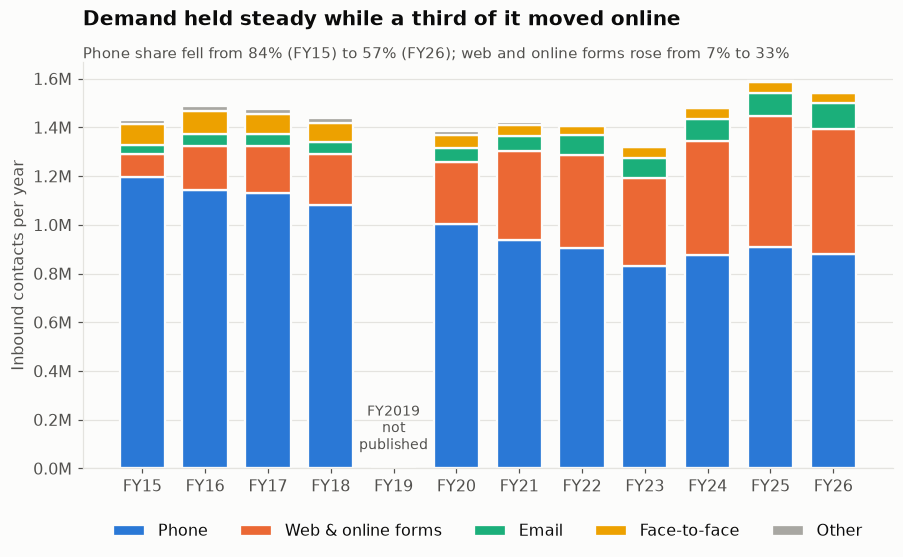

In [4]:
q1 = run(1); q2 = run(2)
display(q1)
mix = q2.pivot(index="financial_year", columns="channel_group", values="inbound").fillna(0)
mix["Other"] = mix[["Mail & fax", "Social media", "SMS"]].sum(axis=1)
groups = ["Phone", "Web & online forms", "Email", "Face-to-face", "Other"]
colors = [S1, S2, S3, S4, OTHER]
share = mix[groups].div(mix[groups].sum(axis=1), axis=0) * 100
display(share.round(1))

years = list(range(2015, 2027))
fig, ax = plt.subplots(figsize=(9.5, 4.8))
x = np.arange(len(years))
bottom = np.zeros(len(years))
for g, c in zip(groups, colors):
    vals = np.array([mix.loc[y, g] if y in mix.index else 0 for y in years])
    ax.bar(x, vals, 0.72, bottom=bottom, color=c, edgecolor=SURFACE, linewidth=1.5, label=g)
    bottom += vals
ax.text(x[years.index(2019)], 60_000, "FY2019\nnot\npublished", ha="center", va="bottom", color=INK2, fontsize=9)
ax.set_xticks(x, [f"FY{str(y)[2:]}" for y in years])
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v/1e6:.1f}M"))
ax.set_ylabel("Inbound contacts per year")
ax.set_title("Demand held steady while a third of it moved online")
ax.text(0, 1.0, "Phone share fell from 84% (FY15) to 57% (FY26); web and online forms rose from 7% to 33%",
        transform=ax.transAxes, color=INK2, fontsize=10, va="bottom")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.1))
ax.grid(axis="x", visible=False)
save(fig, "q1_channel_shift.png")

## Q3. How much phone work has channel shift removed?

,financial_year,calls,avg_calls_per_weekday,change_vs_fy2015_pct
0,2015,1196669,4188.0,0.0
1,2016,1142325,3989.0,-4.5
2,2017,1132714,3975.0,-5.3
3,2018,1082522,3800.0,-9.5
4,2020,1001715,3476.0,-16.3
5,2021,938932,3294.0,-21.5
6,2022,905760,3142.0,-24.3
7,2023,829748,2889.0,-30.7
8,2024,874698,3053.0,-26.9
9,2025,907367,3147.0,-24.2


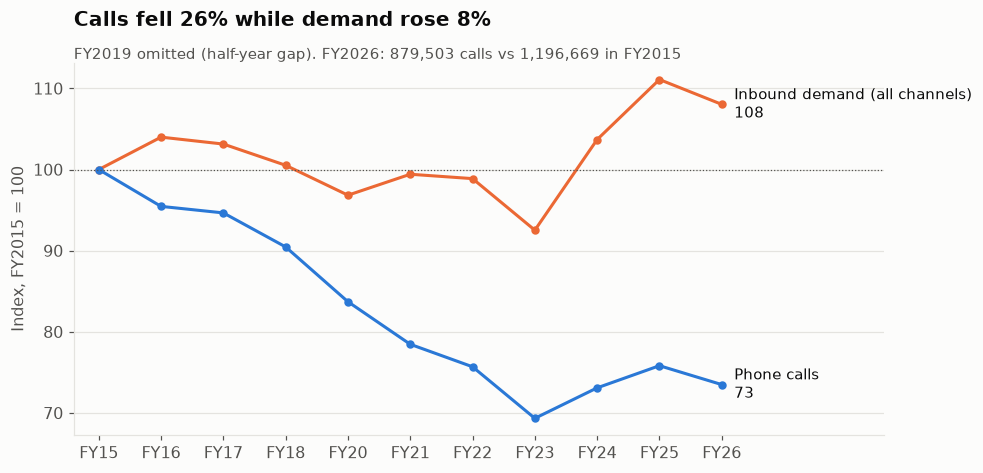

In [5]:
q3 = run(3); display(q3)
idx = q1.set_index("financial_year")["inbound"]
calls = q3.set_index("financial_year")["calls"]
fy = [y for y in years if y != 2019]
fig, ax = plt.subplots(figsize=(9.5, 4.4))
for series, c, lab in [(idx, S2, "Inbound demand (all channels)"), (calls, S1, "Phone calls")]:
    v = series.loc[fy] / series.loc[2015] * 100
    ax.plot(range(len(fy)), v.values, color=c, lw=2, marker="o", ms=4.5)
    ax.text(len(fy) - 0.8, v.values[-1], f"{lab}\n{v.values[-1]:.0f}", color=INK, va="center", fontsize=10)
ax.axhline(100, color=INK2, lw=0.8, ls=":")
ax.set_xticks(range(len(fy)), [f"FY{str(y)[2:]}" for y in fy])
ax.set_xlim(-0.4, len(fy) + 1.6)
ax.set_ylabel("Index, FY2015 = 100")
ax.set_title("Calls fell 26% while demand rose 8%")
ax.text(0, 1.0, "FY2019 omitted (half-year gap). FY2026: 879,503 calls vs 1,196,669 in FY2015",
        transform=ax.transAxes, color=INK2, fontsize=10, va="bottom")
ax.grid(axis="x", visible=False)
save(fig, "q3_calls_vs_demand.png")

## Q4–Q5. Which services drive demand, and how concentrated are calls?

,category,service,fy2026_inbound,share_of_fy2026_pct,phone_share_pct,fy2016_inbound,growth_since_fy2016_pct
0,Property Information Services,Property Searches,111265,7.2,36.0,46453,140.0
1,Waste Collection,Waste Collection Service Management,107850,7.0,56.0,43225,150.0
2,Parking Control,Parking Control Enforcement,107106,6.9,73.0,69739,54.0
3,Waste Collection,Waste Asset Provision,92080,6.0,56.0,86518,6.0
4,Rates Assessment,Rates Maintenance,86516,5.6,55.0,67575,28.0
5,Built Structure Control,Built Structure Permit,65482,4.2,2.0,57102,15.0
6,Animal Control,Animal Permit,62673,4.1,47.0,66556,-6.0
7,Tree Management,Tree Maintenance,58020,3.8,54.0,32960,76.0
8,Call Centre Services,Customer Request Management,57812,3.7,58.0,67944,-15.0
9,Call Centre Services,Lost Property Management,49840,3.2,80.0,46636,7.0


,services_with_calls,services_for_50pct_of_calls,services_for_80pct_of_calls
0,321,10,37


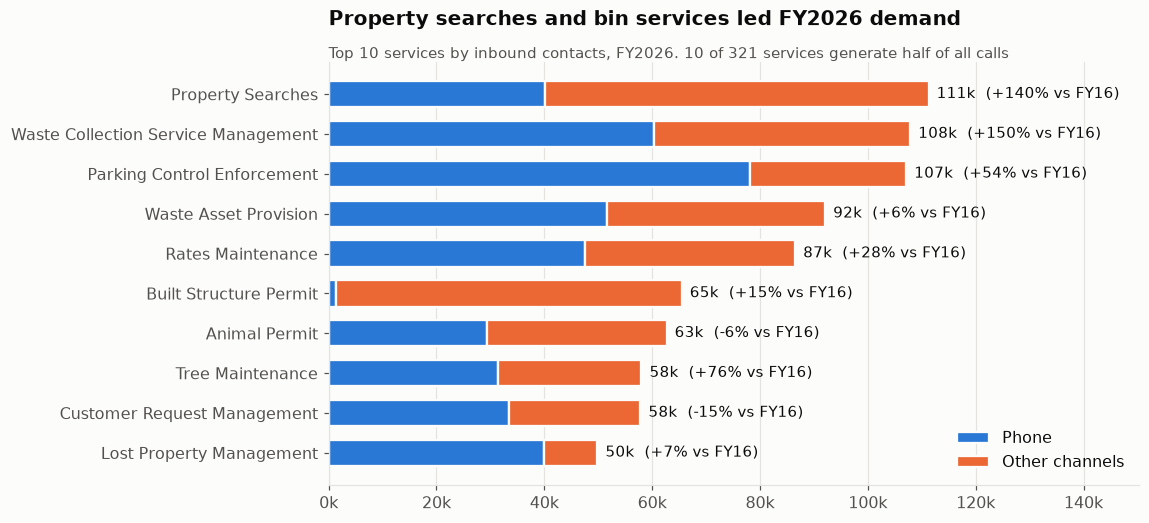

In [6]:
q4 = run(4); q5 = run(5); display(q4); display(q5)
t = q4.iloc[::-1]
calls4 = t.fy2026_inbound * t.phone_share_pct / 100
fig, ax = plt.subplots(figsize=(9.5, 5))
y = np.arange(len(t))
ax.barh(y, calls4, 0.66, color=S1, label="Phone", edgecolor=SURFACE, linewidth=1.5)
ax.barh(y, t.fy2026_inbound - calls4, 0.66, left=calls4, color=S2, label="Other channels", edgecolor=SURFACE, linewidth=1.5)
for yi, (tot, g) in enumerate(zip(t.fy2026_inbound, t.growth_since_fy2016_pct)):
    ax.text(tot + 1500, yi, f"{tot/1e3:,.0f}k  ({g:+.0f}% vs FY16)", va="center", fontsize=9.5, color=INK)
ax.set_yticks(y, t.service)
ax.xaxis.set_major_formatter(thousands)
ax.set_xlim(0, t.fy2026_inbound.max() * 1.35)
ax.set_title("Property searches and bin services led FY2026 demand")
ax.text(0, 1.0, f"Top 10 services by inbound contacts, FY2026. {int(q5.services_for_50pct_of_calls[0])} of "
        f"{int(q5.services_with_calls[0])} services generate half of all calls",
        transform=ax.transAxes, color=INK2, fontsize=10, va="bottom")
ax.legend(loc="lower right"); ax.grid(axis="y", visible=False)
save(fig, "q4_top_services.png")

## Q6. Which large services have not shifted to digital?
Services with ≥ 10,000 inbound contacts in FY2026 that still arrive ≥ 70% by phone. *Calls avoided* is a scenario:
the calls saved if each service fell to the contact centre's overall FY2026 phone share (56.9%).

,category,service,fy2026_inbound,fy2026_calls,phone_share_fy2016_pct,phone_share_fy2026_pct,calls_avoided_at_average
0,Parking Control,Parking Control Enforcement,107106,77735,85.0,73.0,16802.0
1,Call Centre Services,Lost Property Management,49840,39747,81.0,80.0,11393.0
2,Plumbing Control Services,Plumbing Regulation,40446,37835,93.0,94.0,14825.0
3,Waste Treatment and Disposal,Waste Treatment and Disposal,21416,20387,96.0,95.0,8203.0
4,Call Centre Services,Switchboard Services,19040,18411,99.0,97.0,7579.0
5,Animal Control,Domestic Animal Control,22449,16768,81.0,75.0,3997.0
6,Rates Assessment,Rates Entitlements,18088,15900,92.0,88.0,5610.0
7,Revenue Management,Revenue Collection,14009,11246,84.0,80.0,3276.0
8,Amenity Protection,Environment Health Protection,12502,10645,89.0,85.0,3533.0
9,Rates Payment Services,Rates Payment Collection,10850,10213,95.0,94.0,4040.0


Laggard services: 268,594 calls = 30.5% of FY2026 calls; scenario avoids 83,242 calls = 9.5%


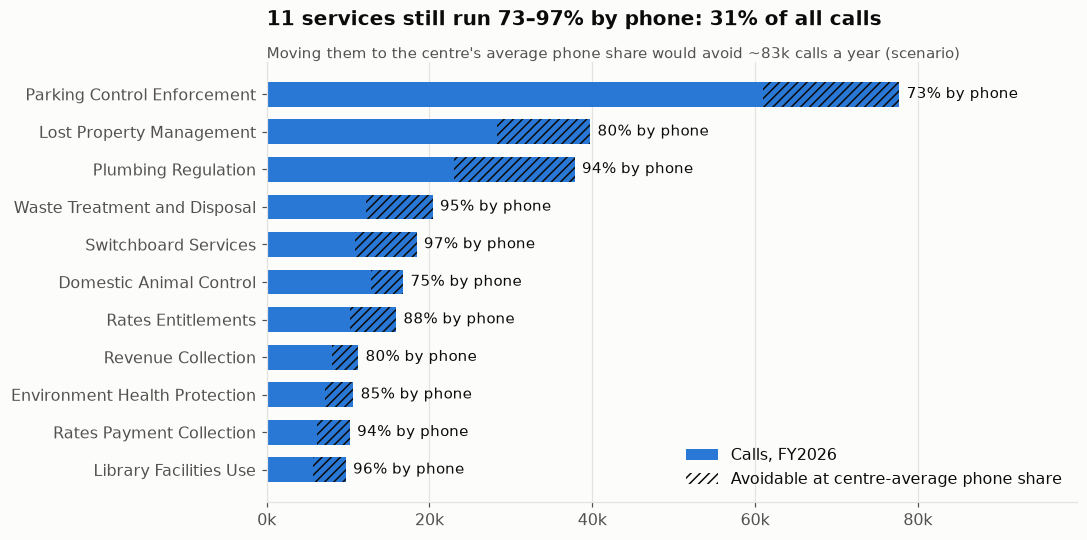

In [7]:
q6 = run(6); display(q6.drop(columns=["laggard_calls_total", "calls_avoided_total"]))
total_calls_26 = calls.loc[2026]
lag_calls, avoided = int(q6.laggard_calls_total[0]), int(q6.calls_avoided_total[0])
print(f"Laggard services: {lag_calls:,} calls = {lag_calls/total_calls_26:.1%} of FY2026 calls; "
      f"scenario avoids {avoided:,} calls = {avoided/total_calls_26:.1%}")
t = q6.iloc[::-1]
fig, ax = plt.subplots(figsize=(9.5, 5.2))
y = np.arange(len(t))
ax.barh(y, t.fy2026_calls, 0.66, color=S1, label="Calls, FY2026")
ax.barh(y, t.calls_avoided_at_average, 0.66, left=t.fy2026_calls - t.calls_avoided_at_average,
        color="none", edgecolor=INK, hatch="////", linewidth=0, label="Avoidable at centre-average phone share")
for yi, (c, p) in enumerate(zip(t.fy2026_calls, t.phone_share_fy2026_pct)):
    ax.text(c + 900, yi, f"{p:.0f}% by phone", va="center", fontsize=9.5)
ax.set_yticks(y, t.service)
ax.xaxis.set_major_formatter(thousands)
ax.set_xlim(0, t.fy2026_calls.max() * 1.28)
ax.set_title(f"11 services still run 73–97% by phone: {lag_calls/total_calls_26:.0%} of all calls")
ax.text(0, 1.0, f"Moving them to the centre's average phone share would avoid ~{avoided/1e3:,.0f}k calls a year (scenario)",
        transform=ax.transAxes, color=INK2, fontsize=10, va="bottom")
ax.legend(loc="lower right"); ax.grid(axis="y", visible=False)
save(fig, "q6_phone_laggards.png")

## Q7. When does phone demand arrive?

,iso_weekday,weekday,avg_calls,days
0,1,Mon,3150.0,52
1,2,Tue,3176.0,53
2,3,Wed,3116.0,52
3,4,Thu,2992.0,52
4,5,Fri,2861.0,52
5,6,Sat,874.0,52
6,7,Sun,683.0,52


,month,avg_calls,seasonality_index
0,1,74446.0,100.0
1,2,79775.0,108.0
2,3,80898.0,109.0
3,4,69115.0,93.0
4,5,75394.0,102.0
5,6,68469.0,92.0
6,7,75187.0,101.0
7,8,78669.0,106.0
8,9,70690.0,95.0
9,10,76154.0,103.0


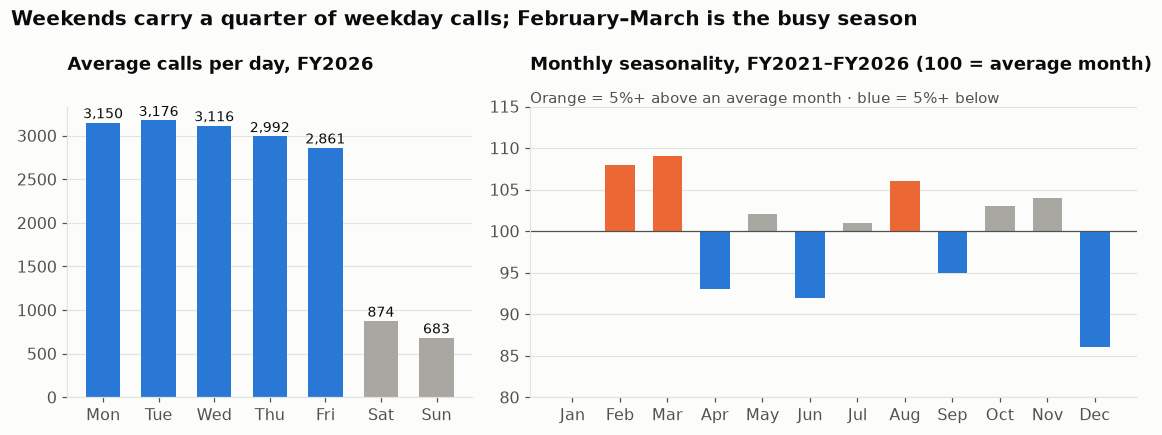

In [8]:
q7a = run(7); q7b = run(8); display(q7a); display(q7b)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10.5, 4), gridspec_kw={"width_ratios": [1, 1.5]})
a1.bar(q7a.weekday, q7a.avg_calls, 0.62, color=[S1] * 5 + [OTHER] * 2)
for i, v in enumerate(q7a.avg_calls): a1.text(i, v + 50, f"{v:,.0f}", ha="center", fontsize=9)
a1.set_title("Average calls per day, FY2026", fontsize=11.5); a1.grid(axis="x", visible=False)
months = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
a2.bar(months, q7b.seasonality_index - 100, 0.62, bottom=100,
       color=[S2 if v >= 105 else (S1 if v <= 95 else OTHER) for v in q7b.seasonality_index])
a2.axhline(100, color=INK2, lw=0.8)
a2.set_ylim(80, 115)
a2.set_title("Monthly seasonality, FY2021–FY2026 (100 = average month)", fontsize=11.5); a2.grid(axis="x", visible=False)
a2.text(0, 1.0, "Orange = 5%+ above an average month · blue = 5%+ below", transform=a2.transAxes,
        color=INK2, fontsize=9.5, va="bottom")
fig.suptitle("Weekends carry a quarter of weekday calls; February–March is the busy season", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
fig.tight_layout()
save(fig, "q7_when_calls_arrive.png")

## Q8. What do demand surges look like?
Days ranked by calls relative to a normal day of the same financial year and day type (median), so the high-volume
early years don't dominate. The two largest surges match the February 2022 Brisbane floods and ex-Tropical Cyclone
Alfred (March 2025) — both on weekends.

,enquiry_date,weekday,calls,typical_calls,times_typical,emergency_calls
0,2022-02-27,Sun,3260,778.0,4.19,1782
1,2025-03-09,Sun,2855,788.0,3.63,641
2,2022-02-26,Sat,2325,778.0,2.99,831
3,2015-05-02,Sat,2134,953.0,2.24,85
4,2025-03-08,Sat,1666,788.0,2.12,323
5,2014-11-29,Sat,2011,953.0,2.11,379
6,2017-04-01,Sat,1732,915.0,1.89,42
7,2022-03-12,Sat,1433,778.0,1.84,426
8,2025-03-15,Sat,1435,788.0,1.82,68
9,2022-03-05,Sat,1403,778.0,1.80,29


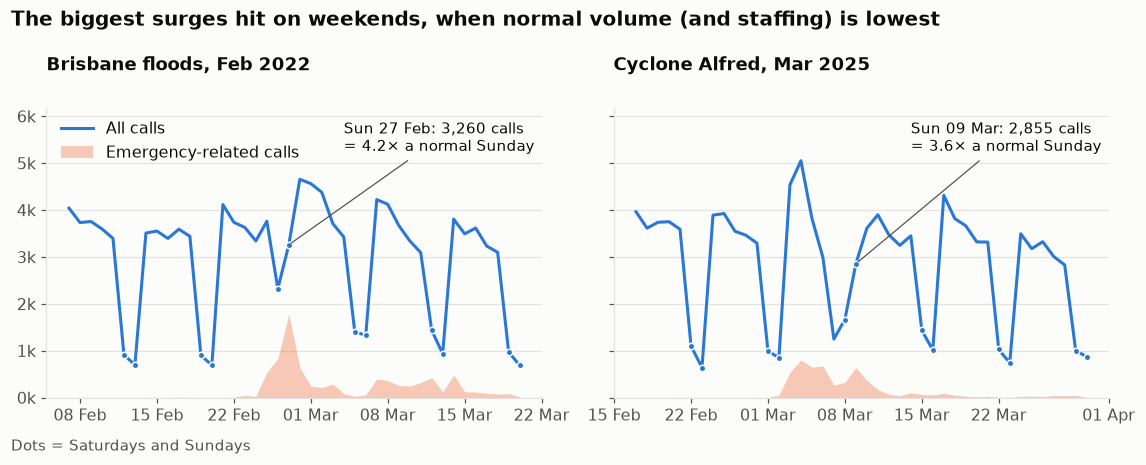

In [9]:
q8 = run(9); display(q8)
daily = q('''SELECT enquiry_date AS ds, SUM(volume) AS calls,
                    SUM(volume) FILTER (WHERE category ILIKE 'Emergency%') AS emergency
             FROM core.fact_daily_enquiries WHERE channel = 'Voice In' GROUP BY 1 ORDER BY 1''')
daily["ds"] = pd.to_datetime(daily.ds); daily = daily.set_index("ds").fillna(0)
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4), sharey=True)
for ax, (a, b, peak, label) in zip(axes, [("2022-02-07", "2022-03-20", "2022-02-27", "Brisbane floods, Feb 2022"),
                                          ("2025-02-17", "2025-03-30", "2025-03-09", "Cyclone Alfred, Mar 2025")]):
    d = daily.loc[a:b]
    ax.plot(d.index, d.calls, color=S1, lw=2, label="All calls")
    ax.fill_between(d.index, 0, d.emergency, color=S2, alpha=0.35, lw=0, label="Emergency-related calls")
    we = d[d.index.dayofweek >= 5]
    ax.scatter(we.index, we.calls, s=18, color=S1, zorder=3, edgecolor=SURFACE, linewidth=1)
    p = pd.Timestamp(peak); r = q8.loc[pd.to_datetime(q8.enquiry_date) == p, "times_typical"].iloc[0]
    ax.annotate(f"{p:%a %d %b}: {d.loc[p,'calls']:,.0f} calls\n= {r:.1f}× a normal {p:%A}",
                (p, d.loc[p, "calls"]), xytext=(p + pd.Timedelta(days=5), 5900), fontsize=9.5, va="top",
                arrowprops=dict(arrowstyle="-", color=INK2, lw=0.8))
    ax.set_ylim(0, 6200)
    ax.set_title(label, fontsize=11.5); ax.yaxis.set_major_formatter(thousands)
    ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%d %b")); ax.grid(axis="x", visible=False)
axes[0].legend(loc="upper left")
fig.suptitle("The biggest surges hit on weekends, when normal volume (and staffing) is lowest", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
fig.text(0.01, -0.02, "Dots = Saturdays and Sundays", color=INK2, fontsize=9.5)
fig.tight_layout()
save(fig, "q8_surges.png")

## Q9. How much does the Council contact customers proactively?

,financial_year,outbound,sms_out,email_out,mail_and_calls_out
0,2015,1202,0.0,305,897
1,2016,4231,0.0,4009,222
2,2017,10319,0.0,9518,801
3,2018,30562,0.0,27042,3520
4,2020,67129,0.0,61431,5698
5,2021,122624,21206.0,95572,5846
6,2022,231754,117289.0,109215,5250
7,2023,272264,157395.0,108365,6504
8,2024,327939,197306.0,124332,6301
9,2025,363587,236157.0,121502,5928


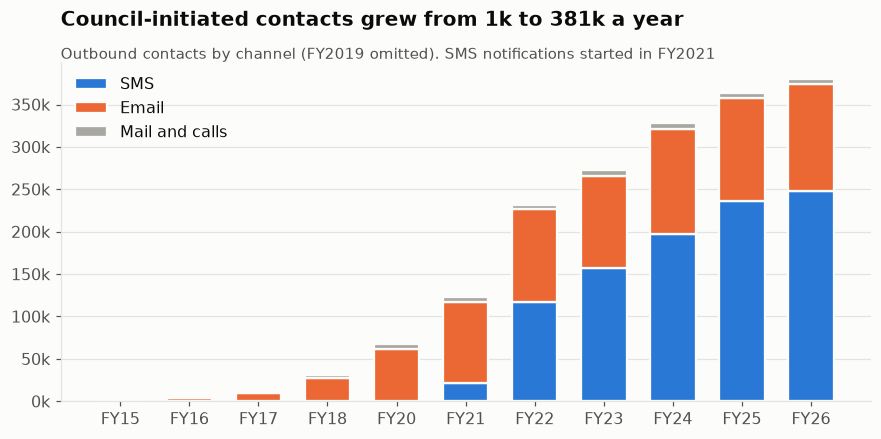

In [10]:
q9 = run(10).fillna(0); display(q9)
fy9 = [f"FY{str(y)[2:]}" for y in q9.financial_year]
fig, ax = plt.subplots(figsize=(9.5, 4))
b = np.zeros(len(q9))
for col, c, lab in [("sms_out", S1, "SMS"), ("email_out", S2, "Email"), ("mail_and_calls_out", OTHER, "Mail and calls")]:
    ax.bar(fy9, q9[col], 0.66, bottom=b, color=c, label=lab, edgecolor=SURFACE, linewidth=1.5); b += q9[col].values
ax.yaxis.set_major_formatter(thousands)
ax.set_title("Council-initiated contacts grew from 1k to 381k a year")
ax.text(0, 1.0, "Outbound contacts by channel (FY2019 omitted). SMS notifications started in FY2021",
        transform=ax.transAxes, color=INK2, fontsize=10, va="bottom")
ax.legend(loc="upper left"); ax.grid(axis="x", visible=False)
save(fig, "q9_outbound.png")

## Forecast. How many calls should the Council plan for in 2027?

**Approach.** Daily calls from 1 Jul 2019 (after the publishing gap) are modelled as a regression with ARIMA errors
on the log scale. Regressors: day of week, Queensland public holidays (`holidays` package), the Christmas–New Year
shutdown (24 Dec – 2 Jan), and annual seasonality (3 Fourier pairs). The ARIMA(1,1,1) error term lets the level drift,
which matters because calls fell through 2023 and then recovered.

**Validation.** The model is trained to 30 Sep 2025 and tested on the 12 months it never saw (Oct 2025 – Sep 2026),
against a **seasonal naive** baseline (each day = the same weekday 52 weeks earlier). Error = WAPE (total absolute
error ÷ total calls), MAPE on regular weekdays, and error on the yearly total. The point forecast is the bias-corrected
mean of the log model (see below).

In [11]:
qld = holidays.Australia(subdiv="QLD", years=range(2019, 2029))
calls_d = q('''SELECT d.calendar_date AS ds, COALESCE(SUM(f.volume), 0) AS y
               FROM core.dim_date d
               LEFT JOIN core.fact_daily_enquiries f ON f.enquiry_date = d.calendar_date AND f.channel = 'Voice In'
               WHERE d.calendar_date >= '2019-07-01' GROUP BY 1 ORDER BY 1''')
y_all = calls_d.assign(ds=pd.to_datetime(calls_d.ds)).set_index("ds").y.astype(float).asfreq("D")

def regressors(idx):
    X = pd.DataFrame(index=idx)
    for k, name in enumerate(["Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], start=1):
        X[name] = (idx.dayofweek == k).astype(int)
    X["qld_holiday"] = [int(d in qld) for d in idx.date]
    X["xmas_shutdown"] = (((idx.month == 12) & (idx.day >= 24)) | ((idx.month == 1) & (idx.day <= 2))).astype(int)
    t = idx.dayofyear / 365.25
    for k in range(1, 4):
        X[f"sin{k}"], X[f"cos{k}"] = np.sin(2 * np.pi * k * t), np.cos(2 * np.pi * k * t)
    return X

def fit(y):
    return SARIMAX(np.log1p(y), exog=regressors(y.index), order=(1, 1, 1)).fit(disp=False, maxiter=200)

def mean_forecast(model, idx):
    # exp() of a log forecast gives the median; adding half the forecast variance gives the mean,
    # which is what capacity planning needs (expected total volume)
    f = model.get_forecast(len(idx), exog=regressors(idx))
    return pd.Series(np.exp(np.asarray(f.predicted_mean) + np.asarray(f.var_pred_mean) / 2) - 1, index=idx)

train, test = y_all[:"2025-09-30"], y_all["2025-10-01":]
m_test = fit(train)
print("Optimizer converged:", m_test.mle_retvals["converged"])
pred = mean_forecast(m_test, test.index)
naive = y_all.shift(364)[test.index]

regular = (test.index.dayofweek < 5) & ~pd.Series([d in qld for d in test.index.date], index=test.index)
def scores(p):
    return {"WAPE %": np.abs(test - p).sum() / test.sum() * 100,
            "Weekday MAPE %": (np.abs(test - p) / test)[regular].mean() * 100,
            "Forecast total": p.sum(), "Actual total": test.sum(),
            "Total error %": (p.sum() / test.sum() - 1) * 100}
val = pd.DataFrame({"Seasonal naive": scores(naive), "Regression + ARIMA": scores(pred)}).T
display(val.round(1))
improve = 1 - val.loc["Regression + ARIMA", "WAPE %"] / val.loc["Seasonal naive", "WAPE %"]
print(f"Model cuts WAPE by {improve:.0%} versus the seasonal naive baseline")

Optimizer converged: True


,WAPE %,Weekday MAPE %,Forecast total,Actual total,Total error %
Seasonal naive,10.6,9.4,911989.0,866661.0,5.2
Regression + ARIMA,8.8,8.5,873897.8,866661.0,0.8


Model cuts WAPE by 17% versus the seasonal naive baseline


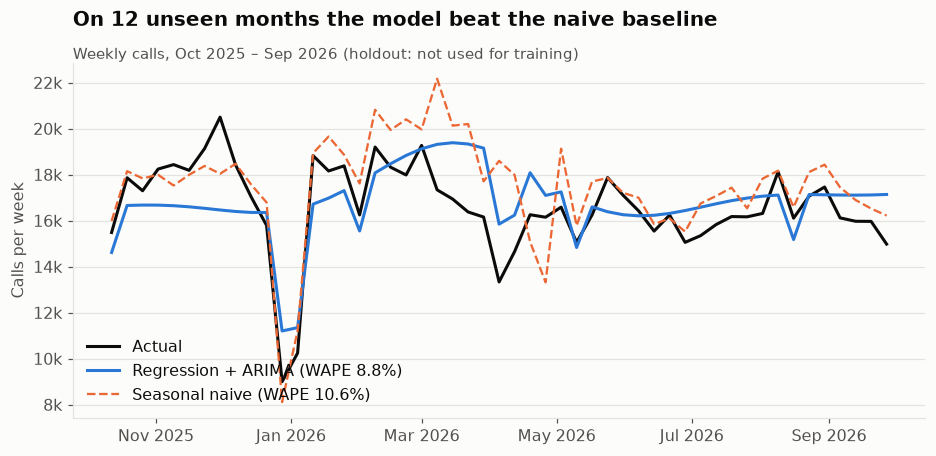

In [12]:
wk = lambda s: s.resample("W-SUN").sum().iloc[1:-1]      # full weeks only
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(wk(test).index, wk(test), color=INK, lw=2, label="Actual")
ax.plot(wk(pred).index, wk(pred), color=S1, lw=2, label=f"Regression + ARIMA (WAPE {val.iloc[1,0]:.1f}%)")
ax.plot(wk(naive).index, wk(naive), color=S2, lw=1.5, ls="--", label=f"Seasonal naive (WAPE {val.iloc[0,0]:.1f}%)")
ax.yaxis.set_major_formatter(thousands); ax.set_ylabel("Calls per week")
ax.set_title("On 12 unseen months the model beat the naive baseline")
ax.text(0, 1.0, "Weekly calls, Oct 2025 – Sep 2026 (holdout: not used for training)",
        transform=ax.transAxes, color=INK2, fontsize=10, va="bottom")
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b %Y"))
ax.legend(loc="lower left"); ax.grid(axis="x", visible=False)
save(fig, "forecast_holdout.png")

**Forecast to December 2027.** The model is refitted on all data to 30 Sep 2026. Because the model works on the log scale,
the point forecast is the bias-corrected **mean** (on the holdout this cut the error on the yearly total from −2.0% to +0.8%,
at the cost of slightly higher daily error). Uncertainty comes from 1,000 simulated paths, summed to months, so the
80% band reflects how daily errors accumulate.

Optimizer converged: True


,Calls
FY2026 actual,879503.0
FY2027 (Jul–Sep actual + forecast),822635.0
Calendar 2027 forecast,823520.0


Calendar 2027: 823,520 calls (80% range 639,356 – 1,052,836)
Average regular weekday 2027: 2,938 calls; busiest month: March (76,332)


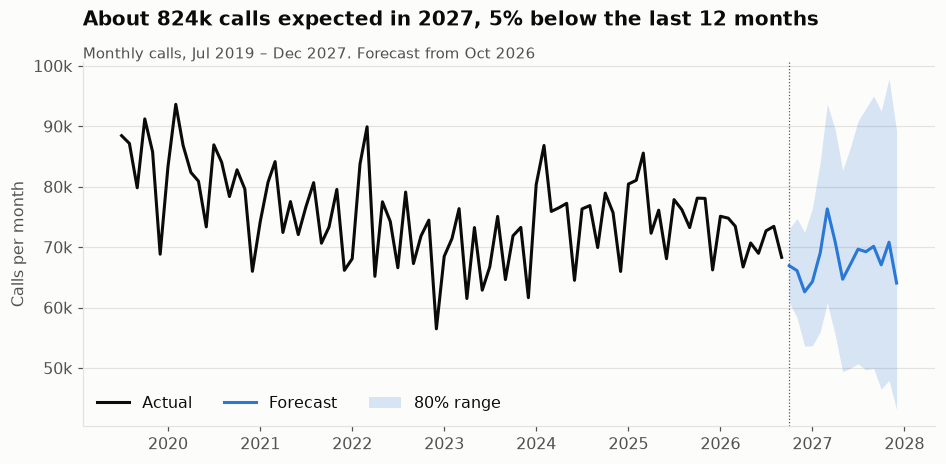

core.forecast_monthly: 102 months written


In [13]:
m_full = fit(y_all)
print("Optimizer converged:", m_full.mle_retvals["converged"])
future = pd.date_range("2026-10-01", "2027-12-31", freq="D")
fc = mean_forecast(m_full, future)
sims = m_full.simulate(len(future), repetitions=1000, anchor="end", exog=regressors(future),
                       rng=np.random.default_rng(2026))
sims = pd.DataFrame(np.expm1(np.asarray(sims).reshape(len(future), -1)), index=future)
monthly_sims = sims.resample("MS").sum()
band = monthly_sims.quantile([0.1, 0.9], axis=1).T
monthly_fc = fc.resample("MS").sum()
hist_m = y_all.resample("MS").sum()

fy2027 = pd.concat([y_all["2026-07-01":], fc[:"2027-06-30"]]).sum()
cal2027 = fc["2027"].sum()
reg27 = fc["2027"][(fc["2027"].index.dayofweek < 5) & ~pd.Series([d in qld for d in fc["2027"].index.date], index=fc["2027"].index)]
summary = pd.DataFrame({
    "Calls": [y_all["2025-07-01":"2026-06-30"].sum(), fy2027, cal2027],
}, index=["FY2026 actual", "FY2027 (Jul–Sep actual + forecast)", "Calendar 2027 forecast"])
cal_band = sims.loc["2027"].sum().quantile([0.1, 0.9])
display(summary.round(0))
print(f"Calendar 2027: {cal2027:,.0f} calls (80% range {cal_band.iloc[0]:,.0f} – {cal_band.iloc[1]:,.0f})")
print(f"Average regular weekday 2027: {reg27.mean():,.0f} calls; busiest month: {monthly_fc['2027'].idxmax():%B} "
      f"({monthly_fc['2027'].max():,.0f})")

fig, ax = plt.subplots(figsize=(10, 4.3))
ax.plot(hist_m[:"2026-09"].index, hist_m[:"2026-09"], color=INK, lw=2, label="Actual")
ax.plot(monthly_fc.index, monthly_fc, color=S1, lw=2, label="Forecast")
ax.fill_between(band.index, band[0.1], band[0.9], color=S1, alpha=0.18, lw=0, label="80% range")
ax.axvline(pd.Timestamp("2026-10-01"), color=INK2, lw=0.8, ls=":")
ax.yaxis.set_major_formatter(thousands); ax.set_ylabel("Calls per month")
last12 = y_all["2025-10-01":"2026-09-30"].sum()
chg = cal2027 / last12 - 1
ax.set_title(f"About {cal2027/1e3:,.0f}k calls expected in 2027, {abs(chg):.0%} {'below' if chg < 0 else 'above'} the last 12 months")
ax.text(0, 1.0, "Monthly calls, Jul 2019 – Dec 2027. Forecast from Oct 2026",
        transform=ax.transAxes, color=INK2, fontsize=10, va="bottom")
ax.legend(loc="lower left", ncol=3); ax.grid(axis="x", visible=False)
save(fig, "forecast_2027.png")

# Store monthly actuals + forecast in PostgreSQL for the Power BI dashboard
fm = pd.DataFrame({"actual_calls": hist_m[:"2026-09"]}).join(
     pd.DataFrame({"forecast_calls": monthly_fc, "forecast_p10": band[0.1], "forecast_p90": band[0.9]}), how="outer")
fm.index.name = "month_start"
fm.round(0).reset_index().to_sql("forecast_monthly", engine, schema="core", if_exists="replace", index=False)
print(f"core.forecast_monthly: {len(fm)} months written")

## Staffing scenario (Erlang C)

The dataset has volumes only — no handle times, wait times or intraday profile — so staffing is a **scenario built on
stated assumptions**, not a measurement. With the Council's telephony data (average handle time and calls by
interval) the same calculation becomes an operational model.

| Assumption | Value | Why |
|---|---|---|
| Peak-hour share of daily calls | 12% | Typical daytime contact-centre profile; replace with interval data |
| Average handle time (AHT) | 6 min (sensitivity 5–7) | Typical for council general enquiries; replace with telephony data |
| Service level target | 80% of calls answered within 60 s | Common public-sector target |
| Shrinkage | 35% | Leave, breaks, training, coaching |

Erlang C gives the agents needed **on the phones** in the peak hour; dividing by (1 − shrinkage) gives rostered staff.

In [14]:
def erlang_c_agents(calls_per_hour, aht_s, target_sl=0.80, answer_s=60):
    A = calls_per_hour * aht_s / 3600                    # traffic in Erlangs
    n = max(1, int(np.ceil(A)) + 1)
    while True:
        b = 1.0                                          # Erlang B by recursion, then Erlang C
        for k in range(1, n + 1):
            b = A * b / (k + A * b)
        c = n * b / (n - A * (1 - b))
        sl = 1 - c * np.exp(-(n - A) * answer_s / aht_s)
        if sl >= target_sl:
            return n, sl, A / n
        n += 1

PEAK_SHARE, SHRINK = 0.12, 0.35
sundays27 = fc["2027"][fc["2027"].index.dayofweek == 6]
mondays27 = fc["2027"][(fc["2027"].index.dayofweek == 0) & ~pd.Series([d in qld for d in fc["2027"].index.date], index=fc["2027"].index)]
surge_ratio = float(q8.times_typical.max())               # largest surge on record (Feb 2022 floods)
scenarios = {
    "Regular Monday 2027": mondays27.mean(),
    "Regular Sunday 2027": sundays27.mean(),
    f"Sunday surge ({surge_ratio:.1f}× normal)": sundays27.mean() * surge_ratio,
}
rows = []
for name, day_calls in scenarios.items():
    cph = day_calls * PEAK_SHARE
    for aht in (300, 360, 420):
        n, sl, occ = erlang_c_agents(cph, aht)
        rows.append({"Scenario": name, "Daily calls": round(day_calls), "Peak-hour calls": round(cph),
                     "AHT (min)": aht / 60, "Agents on phones": n, "Rostered staff": int(np.ceil(n / (1 - SHRINK))),
                     "Service level": f"{sl:.0%}", "Occupancy": f"{occ:.0%}"})
staff = pd.DataFrame(rows)
display(staff)
base = staff[staff["AHT (min)"] == 6].set_index("Scenario")
print(base[["Daily calls", "Peak-hour calls", "Agents on phones", "Rostered staff"]])

# Store the scenario table for the Power BI dashboard
staff.rename(columns=lambda c: re.sub(r"[^a-z0-9]+", "_", c.lower()).strip("_")).to_sql(
    "staffing_scenario", engine, schema="core", if_exists="replace", index=False)
print(f"core.staffing_scenario: {len(staff)} rows written")

,Scenario,Daily calls,Peak-hour calls,AHT (min),Agents on phones,Rostered staff,Service level,Occupancy
0,Regular Monday 2027,3148,378,5.0,36,56,86%,87%
1,Regular Monday 2027,3148,378,6.0,42,65,80%,90%
2,Regular Monday 2027,3148,378,7.0,49,76,82%,90%
3,Regular Sunday 2027,641,77,5.0,9,14,84%,71%
4,Regular Sunday 2027,641,77,6.0,11,17,88%,70%
5,Regular Sunday 2027,641,77,7.0,12,19,83%,75%
6,Sunday surge (4.2× normal),2686,322,5.0,31,48,85%,87%
7,Sunday surge (4.2× normal),2686,322,6.0,37,57,86%,87%
8,Sunday surge (4.2× normal),2686,322,7.0,43,67,86%,87%


                            Daily calls  Peak-hour calls  Agents on phones  Rostered staff
Scenario                                                                                  
Regular Monday 2027                3148              378                42              65
Regular Sunday 2027                 641               77                11              17
Sunday surge (4.2× normal)         2686              322                37              57
core.staffing_scenario: 9 rows written


## Conclusions

The numbers below are printed from the queries and the model above.

In [15]:
s26 = share.loc[2026]; s15 = share.loc[2015]
print(f"1. Demand rose {idx.loc[2026]/idx.loc[2015]-1:+.1%} (FY2015→FY2026) while calls fell {calls.loc[2026]/calls.loc[2015]-1:+.1%}"
      f" ({calls.loc[2015]-calls.loc[2026]:,.0f} fewer a year).")
print(f"2. Phone share {s15['Phone']:.1f}% → {s26['Phone']:.1f}%; web & online forms {s15['Web & online forms']:.1f}% → {s26['Web & online forms']:.1f}%.")
print(f"3. {len(q6)} large services still ≥70% phone: {lag_calls:,} calls ({lag_calls/total_calls_26:.0%}); "
      f"~{avoided:,} avoidable a year at the centre-average phone share (scenario).")
print(f"4. Largest surges are weekend weather events: {q8.enquiry_date[0]} at {q8.times_typical[0]:.1f}× a normal day.")
print(f"5. 2027 forecast: {cal2027:,.0f} calls (80% range {cal_band.iloc[0]:,.0f}–{cal_band.iloc[1]:,.0f}); "
      f"model WAPE {val.iloc[1,0]:.1f}% vs naive {val.iloc[0,0]:.1f}%.")
b = base["Rostered staff"]
print(f"6. Peak-hour rostered phone staff (AHT 6 min): Monday {b.iloc[0]}, Sunday {b.iloc[1]}, Sunday surge {b.iloc[2]}.")

1. Demand rose +8.0% (FY2015→FY2026) while calls fell -26.5% (317,166 fewer a year).
2. Phone share 83.6% → 56.9%; web & online forms 6.6% → 33.4%.
3. 11 large services still ≥70% phone: 268,594 calls (31%); ~83,242 avoidable a year at the centre-average phone share (scenario).
4. Largest surges are weekend weather events: 2022-02-27 at 4.2× a normal day.
5. 2027 forecast: 823,520 calls (80% range 639,356–1,052,836); model WAPE 8.8% vs naive 10.6%.
6. Peak-hour rostered phone staff (AHT 6 min): Monday 65, Sunday 17, Sunday surge 57.
